# Triangulated Maximally Filtered Graph (TMFG)

**Family:** Finance & investment &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Advanced

> *Finance & investment:* Performance, risk, portfolios, markets, rates, derivatives and valuation, the everyday charts of investors and analysts.

> ⚠️ Educational examples with simulated or historical data. Not investment advice; past performance does not predict future returns.

## Design purpose

Filters a dense correlation matrix into a sparse, planar network that keeps the strongest relationships. The minimum spanning tree keeps only n−1 links, so it cuts loops and drops much of the structure. The TMFG grows a planar graph of triangles and 4-cliques with 3n−6 links. It keeps clusters, loops and cross-sector ties, and stays sparse enough to draw and reason about.

## When to use

- Mapping the dependency structure of a portfolio or market (dozens to hundreds of assets)
- Finding hubs and clusters for diversification, risk management or stress testing
- When the MST looks too thin and a threshold network too arbitrary or tangled

## Avoid when

- Only a handful of assets (show the correlation heatmap)
- Readers need exact correlations (use a clustered heatmap)
- Correlations are unstable over the window (filter rolling windows, or show rolling correlation)

## Alternatives

- Correlation network (minimum spanning tree)
- Clustered correlation heatmap or HRP dendrogram
- Planar maximally filtered graph (PMFG), which is slower

## Design tips

- Draw the MST next to the TMFG so readers see what the extra links add
- Size nodes by degree; high-degree hubs transmit shocks and are concentration risks
- Use a correlation-based distance for the layout, so tightly correlated stocks sit together
- TMFG runs in O(n²); PMFG needs O(n³) planarity tests, so TMFG scales to large universes

## Example

Simulated daily returns for 40 stocks in four sectors plus "Other", driven by a market factor, sector factors, and a style factor shared by Tech and Consumer stocks. The same correlation matrix is filtered as an MST (left) and as a TMFG (right).

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

import networkx as nx

### Data

In [2]:
rng = np.random.default_rng(23)
sectors = {"Tech": 10, "Financials": 9, "Energy": 8, "Consumer": 8, "Other": 5}
tickers, sector_of = [], {}
for s, k in sectors.items():
    for i in range(k):
        t = f"{s[:3].upper()}{i + 1}"
        tickers.append(t)
        sector_of[t] = s
n_days = 756                                    # three years of daily returns
market = rng.normal(0.0004, 0.010, n_days)
sector_f = {s: rng.normal(0, 0.007 if s != "Other" else 0.002, n_days) for s in sectors}
style_f = rng.normal(0, 0.006, n_days)          # a cross-sector "growth vs value" factor
rets = pd.DataFrame({
    t: rng.uniform(0.6, 1.3) * market + rng.uniform(0.6, 1.2) * sector_f[sector_of[t]]
       + (rng.uniform(0.4, 0.9) * style_f if sector_of[t] in ("Tech", "Consumer") else 0)
       + rng.normal(0, 0.009, n_days)
    for t in tickers})
corr = rets.corr()
corr.round(2).iloc[:5, :5]

,TEC1,TEC2,TEC3,TEC4,TEC5
TEC1,1.00,0.57,0.61,0.62,0.52
TEC2,0.57,1.00,0.57,0.62,0.50
TEC3,0.61,0.57,1.00,0.68,0.54
TEC4,0.62,0.62,0.68,1.00,0.56
TEC5,0.52,0.50,0.54,0.56,1.00


### Plot

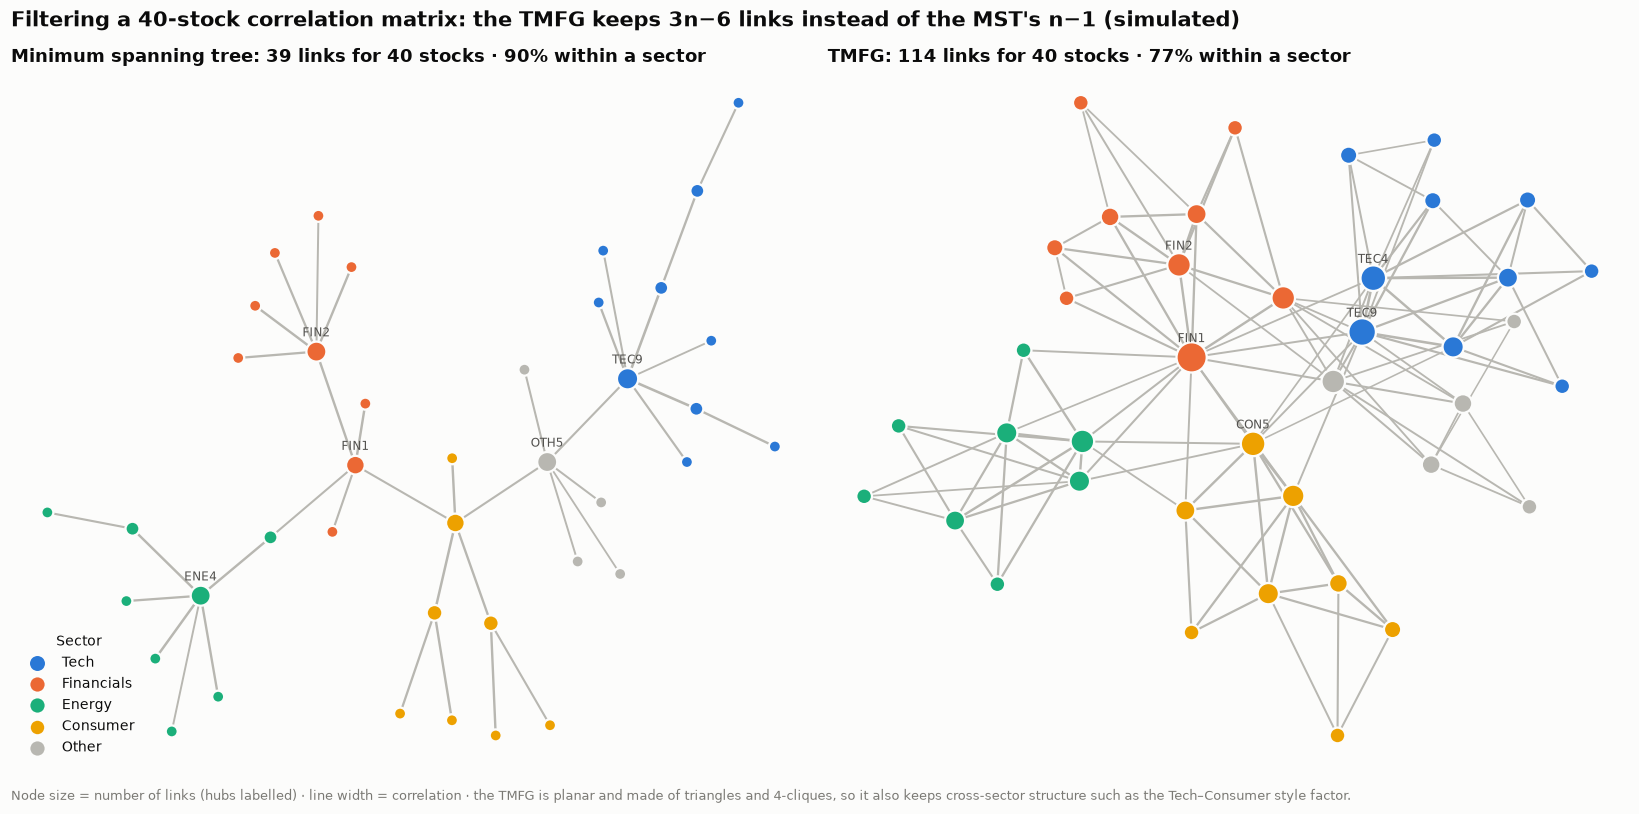

In [3]:
def tmfg(W):
    """Triangulated Maximally Filtered Graph (Massara, Di Matteo & Aste 2016).

    Start from the 4 most connected nodes (a tetrahedron), then repeatedly insert the remaining
    node that adds the largest total weight into one triangular face. Result: planar, 3n-6 edges.
    """
    W = np.asarray(W, float).copy()
    np.fill_diagonal(W, 0)
    n = len(W)
    strength = (W * (W > W.mean())).sum(axis=1)
    clique = list(np.argsort(strength)[::-1][:4])
    edges = {(a, b) for i, a in enumerate(clique) for b in clique[i + 1:]}
    faces = [tuple(f) for f in [(clique[0], clique[1], clique[2]), (clique[0], clique[1], clique[3]),
                                (clique[0], clique[2], clique[3]), (clique[1], clique[2], clique[3])]]
    remaining = [v for v in range(n) if v not in clique]
    while remaining:
        F = np.array(faces)
        gains = W[np.ix_(remaining, F[:, 0])] + W[np.ix_(remaining, F[:, 1])] + W[np.ix_(remaining, F[:, 2])]
        vi, fi = np.unravel_index(np.argmax(gains), gains.shape)
        v, (a, b, c) = remaining.pop(vi), faces.pop(fi)
        edges |= {(v, a), (v, b), (v, c)}
        faces += [(v, a, b), (v, b, c), (v, a, c)]
    return edges


edges_t = tmfg(corr.values)
T = nx.Graph()
T.add_nodes_from(tickers)
T.add_edges_from((tickers[a], tickers[b], {"corr": corr.iloc[a, b]}) for a, b in edges_t)

dist = np.sqrt(2 * (1 - corr))
G = nx.Graph()
for i, a in enumerate(tickers):
    for b in tickers[i + 1:]:
        G.add_edge(a, b, weight=dist.loc[a, b], corr=corr.loc[a, b])
M = nx.minimum_spanning_tree(G, weight="weight")


def within_sector(graph):
    return np.mean([sector_of[a] == sector_of[b] for a, b in graph.edges])


fig, axes = plt.subplots(1, 2, figsize=(15, 7.4))
colors = {s: (PALETTE[k] if s != "Other" else GRAY) for k, s in enumerate(sectors)}
for ax, graph, name in ((axes[0], M, "Minimum spanning tree"), (axes[1], T, "TMFG")):
    lengths = {(a, b): dist.loc[a, b] for a, b in graph.edges}
    nx.set_edge_attributes(graph, lengths, "length")
    pos = nx.kamada_kawai_layout(graph, weight="length")
    for a, b, d in graph.edges(data=True):
        (x1, y1), (x2, y2) = pos[a], pos[b]
        ax.plot([x1, x2], [y1, y2], color="#b8b7b1", linewidth=0.4 + 3 * max(d["corr"] - 0.3, 0), zorder=1)
    deg = dict(graph.degree)
    for s in sectors:
        nodes = [t for t in graph.nodes if sector_of[t] == s]
        xy = np.array([pos[t] for t in nodes])
        ax.scatter(xy[:, 0], xy[:, 1], s=[40 + 22 * deg[t] for t in nodes], color=colors[s],
                   edgecolor="#fcfcfb", linewidth=1.5, zorder=3, label=s)
    hubs = sorted(deg, key=deg.get, reverse=True)[:5]
    for t in hubs:
        ax.annotate(t, pos[t], xytext=(0, 10), textcoords="offset points", ha="center", fontsize=8,
                    color="#52514e", zorder=4)
    ax.set_axis_off()
    ax.set_title(f"{name}: {graph.number_of_edges()} links for {graph.number_of_nodes()} stocks · "
                 f"{within_sector(graph):.0%} within a sector", fontsize=11.5)
axes[0].legend(loc="lower left", title="Sector", fontsize=9, title_fontsize=9)
fig.suptitle("Filtering a 40-stock correlation matrix: the TMFG keeps 3n−6 links instead of the MST's n−1 (simulated)",
             x=0.01, ha="left", fontsize=13.5, fontweight="bold")
fig.text(0.01, 0.01, "Node size = number of links (hubs labelled) · line width = correlation · "
         "the TMFG is planar and made of triangles and 4-cliques, so it also keeps cross-sector structure "
         "such as the Tech–Consumer style factor.", fontsize=8.5, color="#7a7974")
fig.tight_layout(rect=(0, 0.03, 1, 1))
plt.show()

## How to read it

Both networks group stocks by sector. The MST has 39 links and forms a tree, so each sector hangs off a single branch. The TMFG has 114 links and adds the triangles inside each sector and the cross links between Tech and Consumer created by the shared style factor. Large nodes are hubs, the stocks most correlated with many others.

## Reference

This method comes from the research literature:

- Massara, G. P., Di Matteo, T. & Aste, T. (2016). Network filtering for big data: triangulated maximally filtered graph. Journal of Complex Networks 5(2), 161–178. <https://arxiv.org/abs/1505.02445>

---
Standalone script: [`tmfg_network.py`](tmfg_network.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)